### 다중 분류 실습 문제

## Intel Image Dataset
: 자연 풍경 및 도시 환경 사진을 6개 클래스로 분류하는 이미지 데이터셋, 클러스터링

- 학습데이터 : 약 14,000
- 테스트 데이터 : 약 3,000
- 예측용 데이터 : 약 7,000
- 이미지 크기 : 150 x 150(컬러 이미지)
- 입력 이미지 : RGB 이미지 (64× 64로 크기 변경)
- 입력 특징 수: 3 × 64 × 64 = 12,288
- 출력 클래스: 6개

| 클래스 이름 | 의미 |
|:---:|:---|
| `buildings` | 건물 |
| `forest` | 숲 |
| `glacier` | 빙하 |
| `mountain` | 산 |
| `sea` | 바다 |
| `street` | 거리 |

#### STEP 1. 데이터 불러오기 및 전처리

**실습 조건**
- `torchvision.datasets.ImageFolder`를 이용해 학습 데이터와 테스트 데이터를 불러온다.
- 이미지를 `(64, 64)` 크기로 통일한다.
- `transforms.ToTensor()`를 이용해 Tensor로 변환한다.
- RGB 이미지이므로 이미지 한 장의 형태는 `[3, 64, 64]`이다.
- `ImageFolder`가 부여한 클래스 인덱스와 클래스 이름을 확인한다.
- 학습 데이터와 테스트 데이터의 클래스 순서가 같은지 확인한다.
- 데이터 개수와 첫 번째 이미지의 shape을 출력한다.

In [1]:
# 데이터를 다운로드 하려면 설치 필요
%pip install kagglehub

  Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl.metadata (2.4 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl (154 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/5 [tqdm]
   ---------------------------------------- 0/5 [tqdm]
   -------- ------------------------------- 1/5 [pyyaml]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ---------------- ----------------------- 2/5 [protobuf]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ --------------- 3/5 [kagglesdk]
   ------------------------ -----

In [2]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
# 이미지 다운로드
import kagglehub
import shutil

# 저장 위치
data_dir = os.path.join(os.getcwd(), "data")

# 1. KaggleHub에서 데이터셋 가져오기
dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print("Kaggle 데이터 위치:", dataset_path)

# 2. data에 복사
os.makedirs(data_dir, exist_ok=True)

shutil.copytree(
    dataset_path,
    data_dir,
    dirs_exist_ok=True
)

print("저장 완료!")
print("최종 저장 위치:", data_dir)

c:\Users\mega\KYJ\PyTorch\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 346M/346M [00:11<00:00, 30.8MB/s] 

Extracting files...


Kaggle 데이터 위치: C:\Users\mega\.cache\kagglehub\datasets\puneet6060\intel-image-classification\versions\2
저장 완료!
최종 저장 위치: c:\Users\mega\KYJ\PyTorch\04.multiclass\data


In [7]:
# 이미지 전처리 및 Totensor() 설정
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

train_DS = datasets.ImageFolder(root='data/seg_train/seg_train', transform=transform)
test_DS = datasets.ImageFolder(root='data/seg_test/seg_test', transform=transform)

#### STEP 2. DataLoader 생성 및 데이터 확인

**실습 조건**
- 학습률(LR): `1e-3`
- Epoch: 10 이상
- Batch size: 32
- Optimizer: Adam
- Loss function: CrossEntropyLoss
- 학습 데이터는 `shuffle=True`, 테스트 데이터는 `shuffle=False`로 설정한다.
- 첫 번째 배치의 `x_batch`, `y_batch` shape을 확인한다.
- 이미지를 시각화하고 이미지의 클래스 이름을 표시한다.

In [9]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 15
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'MLP_deep'
dataset = 'CIFAR10'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [10]:
train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size= BATCH_SIZE, shuffle=True)

In [11]:
print(train_DS)
print(test_DS)
print(test_DS.classes)
print(test_DS.class_to_idx)

Dataset ImageFolder
    Number of datapoints: 14034
    Root location: data/seg_train/seg_train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )
Dataset ImageFolder
    Number of datapoints: 3000
    Root location: data/seg_test/seg_test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


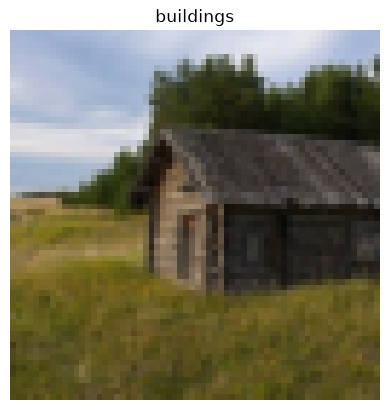

In [14]:
image, label = train_DS[99]

plt.imshow(image.permute(1, 2, 0))
plt.title(train_DS.classes[label])
plt.axis('off')
plt.show()

torch.Size([32, 3, 64, 64])
street


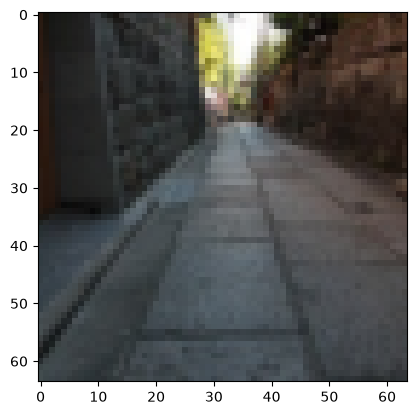

In [15]:
x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

plt.imshow(x_batch[0].permute(1,2,0))
print(test_DS.classes[y_batch[0]])

#### STEP 3. MLP 모델 만들기

**모델 조건**

- 입력 이미지 크기: `[3, 64, 64]`
- `torch.flatten(x, start_dim=1)`을 이용해 배치 차원은 유지하고 나머지 차원을 펼친다.
- 입력 특징 수: `3 × 64 × 64`<br><br>

- 3가지의 모델 정의하기
    1. 은닉층 노드 수: 30개
    2. 은닉층 노드 수: 100개
    3. 여러개의 은닉층 

In [16]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(
        nn.Linear(3*64*64, 30),
        nn.BatchNorm1d(30),  
        nn.ReLU(),
        nn.Linear(30, 10)
    )

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

# 은닉층 뉴런의 개수를 늘림: 30 -> 100
class MLP_shallow(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(
        nn.Linear(3*64*64, 100),  
        nn.BatchNorm1d(100),  
        nn.ReLU(),
        nn.Linear(100, 10)
    )

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

# 은닉층의 층수를 늘림: 4 -> 34
class MLP_deep(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(
        nn.Linear(3*64*64, 30),
        nn.BatchNorm1d(30),
        nn.ReLU(),
        *[i for _ in range(10) for i in [nn.Linear(30, 30),
                                         nn.BatchNorm1d(30), 
                                         nn.ReLU()]],
        nn.Linear(30, 10)
    )

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

In [17]:
model = globals()[model_type]().to(device)
print(model)
# model_type 은 하이퍼 파라미터 셀에서 model_type = 'MLP' 로 정의했기 때문에 변경희망시
# model_type = 'MLP_shallow' 로 변경하여 다시 셀 2 개를 실행하면 됨

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)
print(model(x_batch.to(device)).shape)

MLP_deep(
  (linear): Sequential(
    (0): Linear(in_features=12288, out_features=30, bias=True)
    (1): BatchNorm1d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=30, out_features=30, bias=True)
    (4): BatchNorm1d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=30, out_features=30, bias=True)
    (7): BatchNorm1d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Linear(in_features=30, out_features=30, bias=True)
    (10): BatchNorm1d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): Linear(in_features=30, out_features=30, bias=True)
    (13): BatchNorm1d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (14): ReLU()
    (15): Linear(in_features=30, out_features=30, bias=True)
    (16): BatchNo

#### STEP 4. 모델 학습시키고 저장하기

In [ ]:
# if new_model_train == True:
if new_model_train:
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.figure()
  plt.plot(range(1, EPOCH+1), loss_history)
  plt.xlabel('ep')
  plt.ylabel('loss')
  plt.title('TR LOSS')
  plt.grid()

In [ ]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

#### STEP 5. 테스트 및 그래프

In [ ]:
Test(load_model, test_DL)
print(count_params(load_model))

In [ ]:
Test_plot(load_model, test_DL)

In [ ]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion)

#### STEP 7. 모델 파라미터 개수 확인

In [ ]:
print(test_params())